In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
df = pd.read_csv("exoplanet_data.csv", comment="#")

In [13]:
print(f"the shape of the datset is {df.shape}")
print("there are 599 rows and 92 columns")
print(df.columns.tolist())
print("sy_snum, sy_pnum, pl_controv_flag, pl_orbper, pl_orbpererr1")

"""ArithmeticError
Table Label: planet Name
Database Column Name: pl_name
Description: the commonly used name of the planet.

Table Label: host name
Database Column Name: hostname
Description: the name of the star that the planet orbits.

Table Label: discovery method
database Column Name: discoverymethod
Description: the scientific technique used to first detect the planet.

Table Label: spectral type
Database Column Name: st_spectype
Description: the classification of the host star based on its temperature, color, and spectral characteristics

Table Label: equilibrium Temperature [K]
Database Column Name: pl_eqt
Description: the estimated temperature of the planet assuming it is heated by its host star and behaves like a blackbody

Table Label: planet Mass or Mass*sin(i) [Jupiter Mass]
Database Column Name: pl_bmassj
Description: the planet's estimated mass measured in Jupiter masses.
Depending on the available measurements, this can be the actual mass
or a minimum mass estimate 
"""

columns_needed = [
    'pl_name',
    'hostname',
    'discoverymethod',
    'st_spectype',
    'pl_eqt',
    'pl_bmassj'
]

df_small = df[columns_needed].copy()

df_clean = df_small.dropna()
print("Shape of cleaned dataset:", df_clean.shape)
print("Number of rows:", df_clean.shape[0])
print("Number of columns:", df_clean.shape[1])
print("\nFirst five rows:")
print(df_clean.head())
print("\nLast five rows:")
print(df_clean.tail())
print("\nColumn titles:")
print(df_clean.columns.tolist())

discovery_counts = df_clean['discoverymethod'].value_counts()

print(discovery_counts)

print("\nNumber of different discovery methods:",
      len(discovery_counts))

print("\nMost common discovery method:",
      discovery_counts.idxmax())

print("\nLeast common discovery method:",
      discovery_counts.idxmin())



the shape of the datset is (599, 92)
there are 599 rows and 92 columns
['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum', 'discoverymethod', 'disc_year', 'disc_facility', 'soltype', 'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1', 'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1', 'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1', 'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2', 'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2', 'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2', 'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1', 'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff', 'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1', 'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2', 'st_masslim', 'st_met',

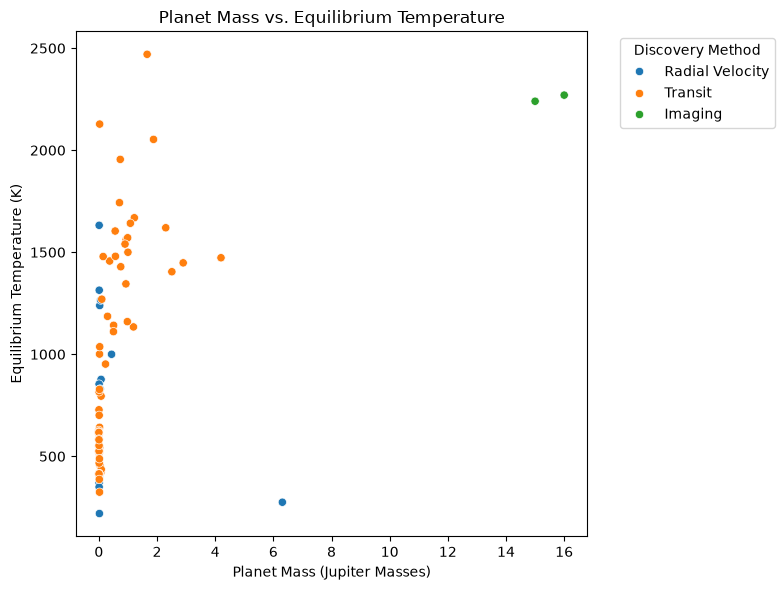

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_clean,
    x='pl_bmassj',
    y='pl_eqt',
    hue='discoverymethod',
    palette='tab10'
)

plt.title('Planet Mass vs. Equilibrium Temperature')
plt.xlabel('Planet Mass (Jupiter Masses)')
plt.ylabel('Equilibrium Temperature (K)')
plt.legend(title='Discovery Method', bbox_to_anchor=(1.05, 1),
           loc='upper left')

plt.tight_layout()
plt.show()

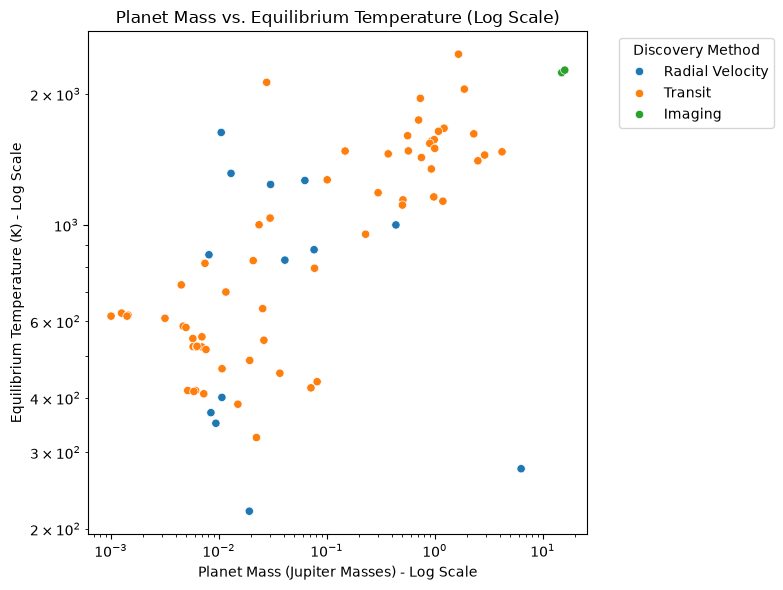

In [15]:

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_clean,
    x='pl_bmassj',
    y='pl_eqt',
    hue='discoverymethod',
    palette='tab10'
)

plt.xscale('log')
plt.yscale('log')
plt.title('Planet Mass vs. Equilibrium Temperature (Log Scale)')
plt.xlabel('Planet Mass (Jupiter Masses) - Log Scale')
plt.ylabel('Equilibrium Temperature (K) - Log Scale')
plt.legend(title='Discovery Method', bbox_to_anchor=(1.05, 1),
           loc='upper left')

plt.tight_layout()
plt.show()


In [ ]:
massive_planets = df_clean[df_clean['pl_bmassj'] > 5]
coldest_index = massive_planets['pl_eqt'].idxmin()
coldest_planet = df_clean.loc[coldest_index]

print("Coldest planet with mass greater than 5 Jupiter masses:")
print(coldest_planet)
print("\nPlanet name:", coldest_planet['pl_name'])
print("Index:", coldest_index)
print("Equilibrium temperature (K):", coldest_planet['pl_eqt'])
print("Mass (Jupiter masses):", coldest_planet['pl_bmassj'])
print("Host star:", coldest_planet['hostname'])
print("Spectral type:", coldest_planet['st_spectype'])



In [ ]:

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_clean,
    x='pl_bmassj',
    y='pl_eqt',
    hue='discoverymethod',
    palette='tab10'
)

plt.scatter(
    coldest_planet['pl_bmassj'],
    coldest_planet['pl_eqt'],
    color='red',
    marker='*',
    s=250,
    edgecolor='black',
    label=coldest_planet['pl_name'],
    zorder=10
)

plt.xscale('log')
plt.yscale('log')

plt.title('Planet Mass vs. Equilibrium Temperature (Log Scale)')
plt.xlabel('Planet Mass (Jupiter Masses)')
plt.ylabel('Equilibrium Temperature (K)')

plt.legend(title='Discovery Method / Highlighted Planet',
           bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
""""
the title is:
'A temperature super-Jupiter imaged with JWST in the mid-infrared'

summarize
the paper describes the discover of a giant exoplanet orbiting the star Epsilon Indi A. People have used the James Webb Space Telescope to photograph the planet using infrared imaging. 

does it match: 
yes, my code matches the paper

what is special: 
The planet is slightly unusual because it's a lot colder and older than most exoplanets that were previously photographed. it's temp is approximately 275 K, which is similar to Earth's temp. It may also have unusual atmospheric composition (high metallicity and carbon to oxygen ratio).

do mass and equilibrium temp match the paper?
yes, the mass and equilibrium are consistent

"""